# Лабораторная работа № 2
## Визуальный анализ данных
**Цель работы**: изучить программные средства, используемые для визуализации наборов данных.

Проанализируем датасет salary. Датасет содержит информацию о рабочих разных профессий и информацию об их работе.

**Признаки**: 
* age – возраст 
* workclass – класс работы 
* fnlwgt –  колонка, которая показывает сколько людей с такими же характеристиками существует
* education – образование 
* education-num – (в задании не указано. скорее всего, кол-во высших образований у человека)
* marital-status – семейное положение 
* occupation – вид деятельности 
* relationship – степень родства 
* race – раса 
* sex – пол 
* capital-gain – прирост капитала 
* capital-loss – убыток капитала 
* hours-per-week – часов в неделю 
* native-country – страна происхождения 
* salary – зарплата


### 0. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
%matplotlib inline

### 1. Загрузка датасета salary.csv

In [2]:
data = pd.read_csv('salary.csv', skipinitialspace=True)
data.head(10)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,salary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
5,37,Private,284582,Masters,14,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
6,49,Private,160187,9th,5,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,16,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States,>50K
8,31,Private,45781,Masters,14,Never-married,Prof-specialty,Not-in-family,White,Female,14084,0,50,United-States,>50K
9,42,Private,159449,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,5178,0,40,United-States,>50K


## 2. Получим сводную информацию по датафрейму

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  salary          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


## 3. Визуализация количественных признаков
* Распределение простого количественного признака: часы работы в неделю

<Axes: >

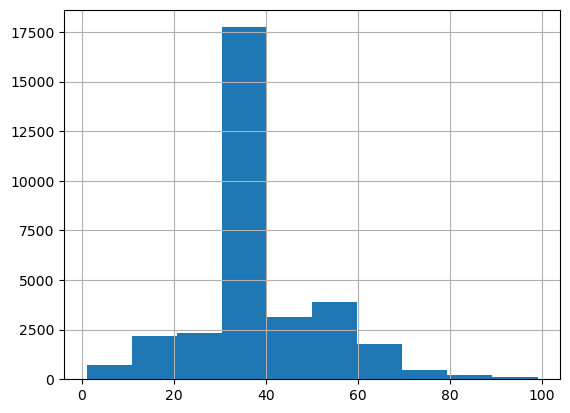

In [4]:
data['hours-per-week'].hist()

* Визуализация распределения нескольких признаков

array([[<Axes: title={'center': 'age'}>,
        <Axes: title={'center': 'fnlwgt'}>],
       [<Axes: title={'center': 'education-num'}>,
        <Axes: title={'center': 'capital-gain'}>],
       [<Axes: title={'center': 'capital-loss'}>,
        <Axes: title={'center': 'hours-per-week'}>]], dtype=object)

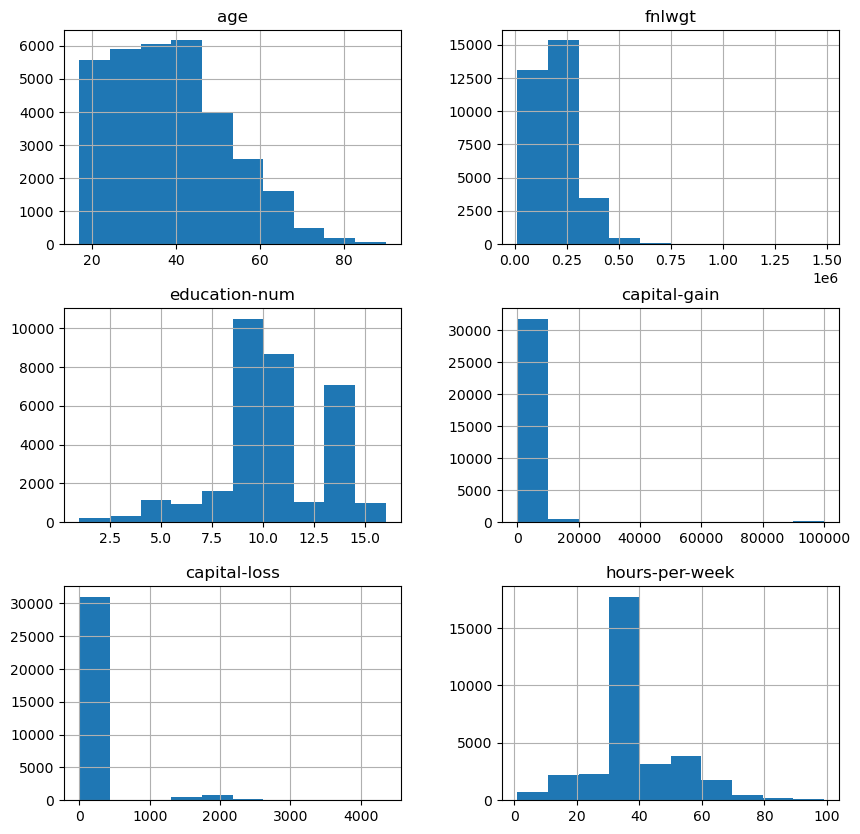

In [5]:
data.hist(figsize=(10, 10))

* График с использованием matplotlib

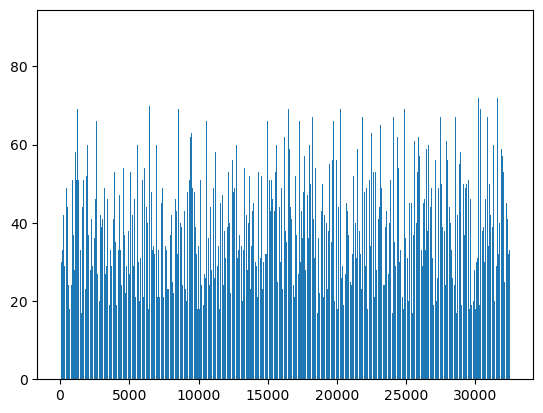

In [6]:
plt.bar(data.index, data['age'])
plt.show()

* График распределения

<BarContainer object of 73 artists>

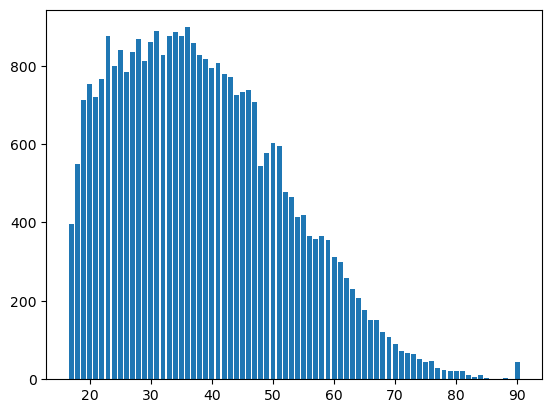

In [7]:
hist = data['age'].value_counts()
plt.bar(hist.index, hist.values)

* Диаграмма типа "ящик с усами"

<Axes: ylabel='age'>

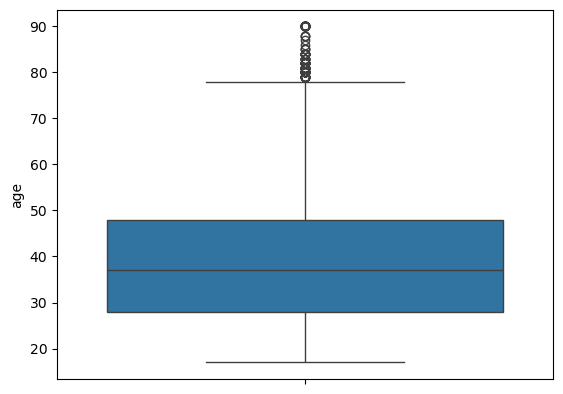

In [8]:
sns.boxplot(data['age'])

* Анализ трёх стран с максимальным количеством часов работы в неделю у рабочих

<Axes: xlabel='hours-per-week', ylabel='native-country'>

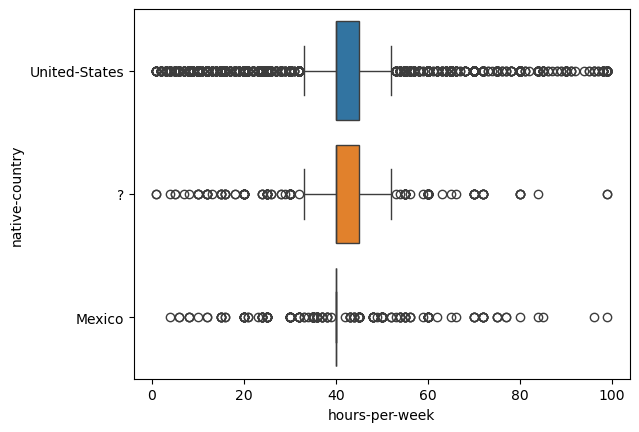

In [9]:
top_data = data[['native-country', 'hours-per-week']].groupby('native-country').sum()
top_data = top_data.sort_values('hours-per-week', ascending=False)[:3].index.values
sns.boxplot(y='native-country', x='hours-per-week', data=data[data['native-country'].isin(top_data)], hue='native-country')

## 4. Визуализация категориальных признаков

* Бинарный категориальный признак пола

In [10]:
data['sex'].value_counts()

sex
Male      21790
Female    10771
Name: count, dtype: int64

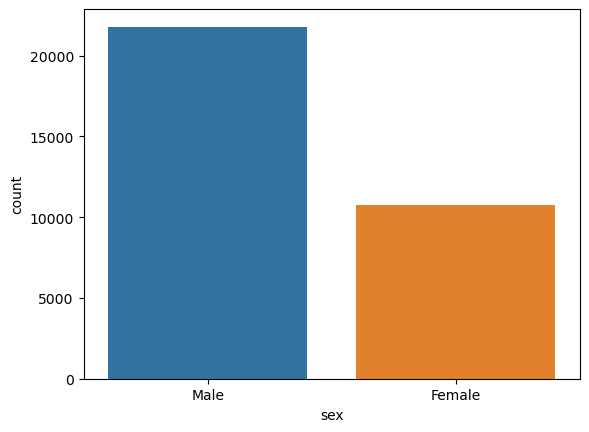

In [11]:
sns.countplot(data, x='sex', hue='sex')
plt.show()

* Гистограмма пяти популярных стран

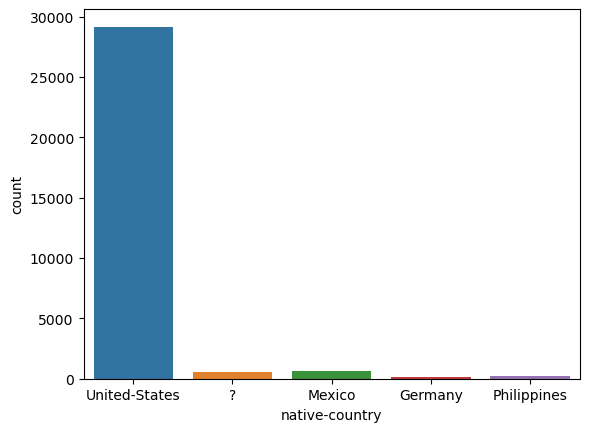

In [12]:
sns.countplot(data[data['native-country'].isin(data['native-country'].value_counts().head(5).index)],
             x='native-country', hue='native-country')
plt.show()

* Для всех стран

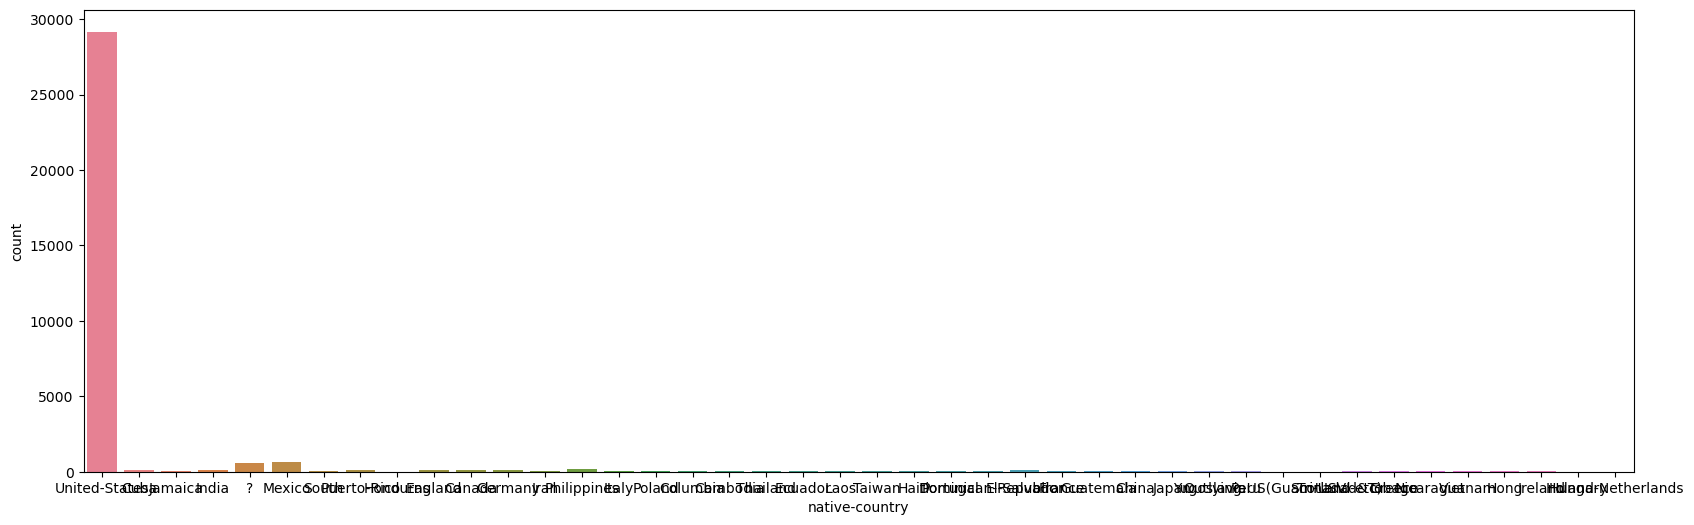

In [13]:
fig = plt.subplots(figsize=(20, 6))
sns.countplot(data, x='native-country', hue='native-country')
plt.show()

* Столбчатая диаграмма

<BarContainer object of 42 artists>

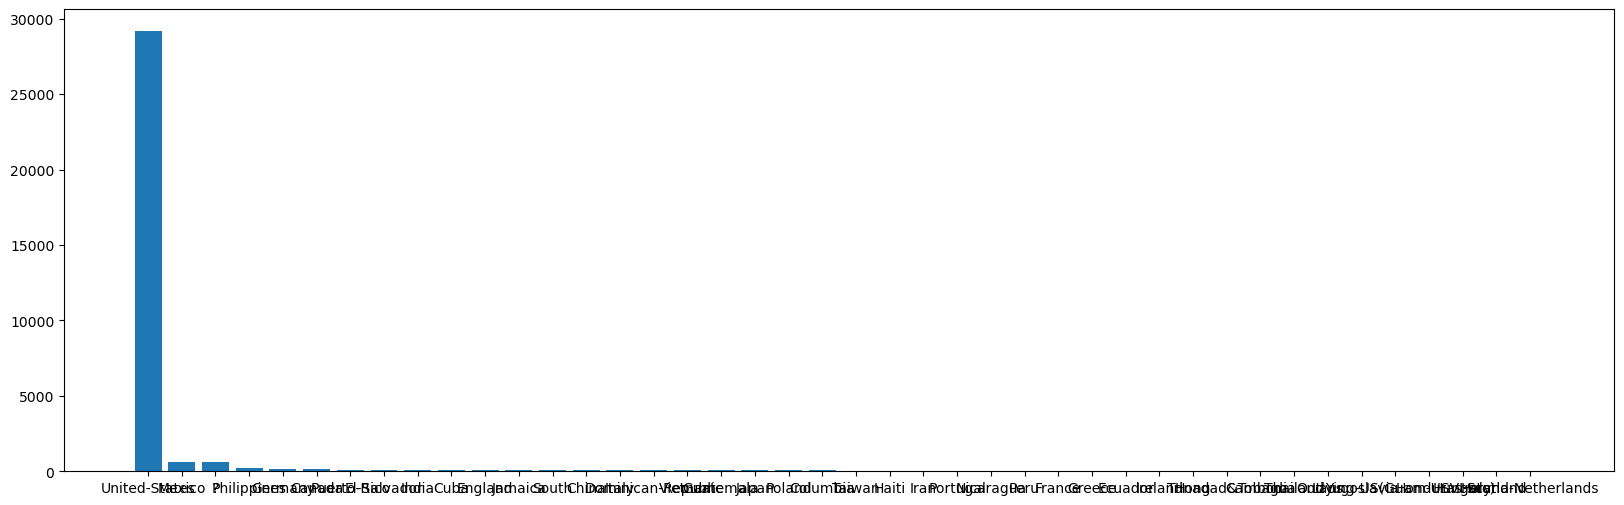

In [14]:
fig = plt.subplots(figsize=(20, 6))
hist = data['native-country'].value_counts()
plt.bar(hist.index, hist)

## 5. Визуализация взаимосвязанных признаков

Рассмотрим пример, демонстрирующий сравнение распределений показателей, связанных с капиталом рабочих. 

In [15]:
data.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'salary'],
      dtype='object')

* Отбор числовых признаков

In [16]:
capital = [i for i in data.columns if 'capital' in i]
capital

['capital-gain', 'capital-loss']

* Для каждого признака построен график

array([[<Axes: title={'center': 'capital-gain'}>,
        <Axes: title={'center': 'capital-loss'}>]], dtype=object)

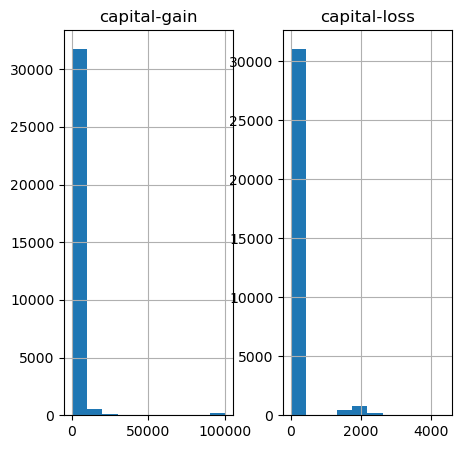

In [17]:
data[capital].hist(figsize=(5, 5))

* Попарное распределение признаков

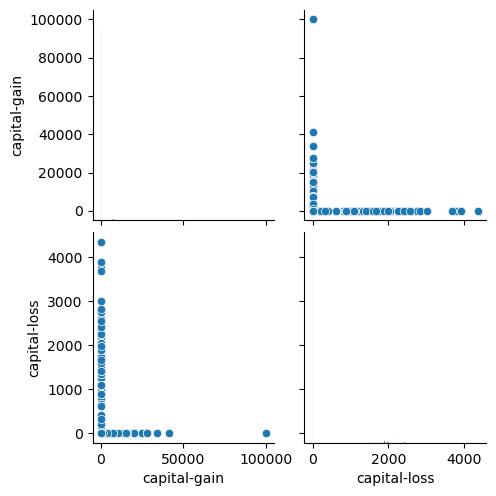

In [18]:
sns.pairplot(data[capital])

* Добавлено подмножество "часы работы в неделю"

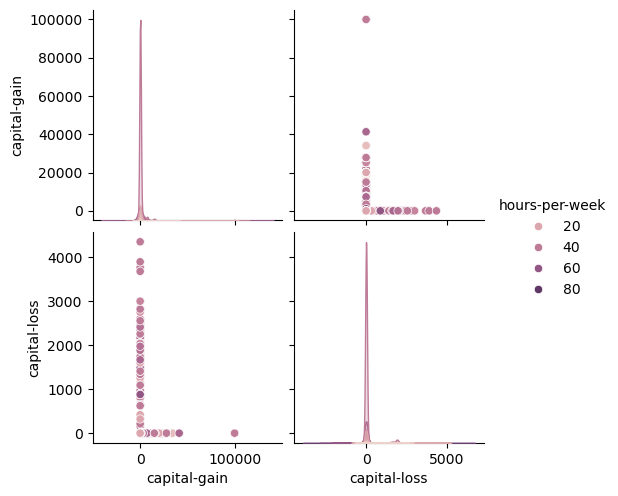

In [19]:
sns.pairplot(data[capital + ['hours-per-week']], hue='hours-per-week')

* Использование распределения, подписей, заголовков и цветов

Text(0.5, 1.0, 'Распределение по 2 признакам')

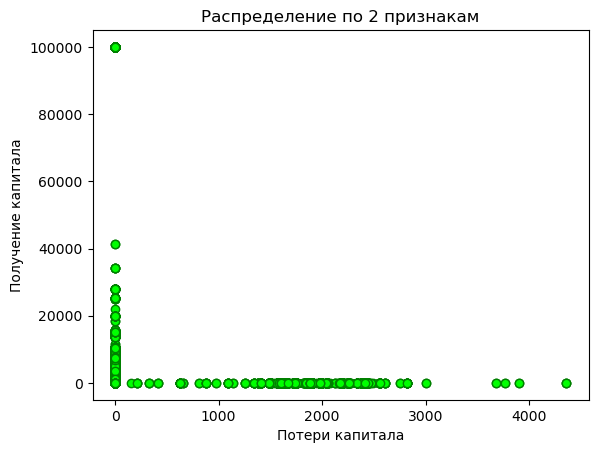

In [20]:
plt.scatter(data['capital-loss'], data['capital-gain'], color='lime', edgecolors='green')

plt.xlabel('Потери капитала')
plt.ylabel('Получение капитала')
plt.title('Распределение по 2 признакам')

* Цвет в зависимости от пола

Text(0.5, 1.0, 'Распределение по 2 признакам')

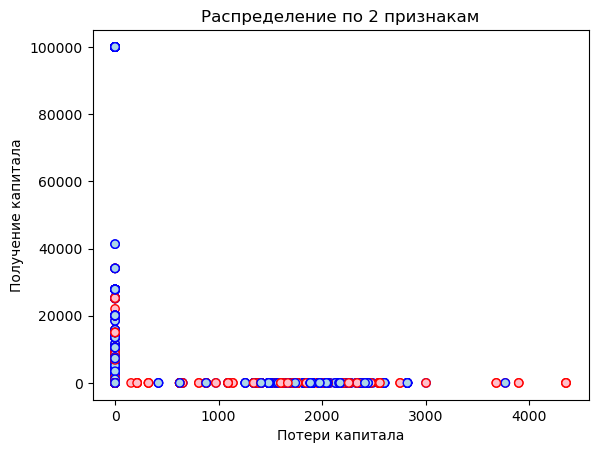

In [21]:
c = data['sex'].map({'Male': 'lightblue', 'Female': 'pink'})
edge_c = data['sex'].map({'Male': 'blue', 'Female': 'red'})

plt.scatter(data['capital-loss'], data['capital-gain'], color=c, edgecolors=edge_c)
plt.xlabel('Потери капитала')
plt.ylabel('Получение капитала')
plt.title('Распределение по 2 признакам')

* Распределение полов, добавление легенды

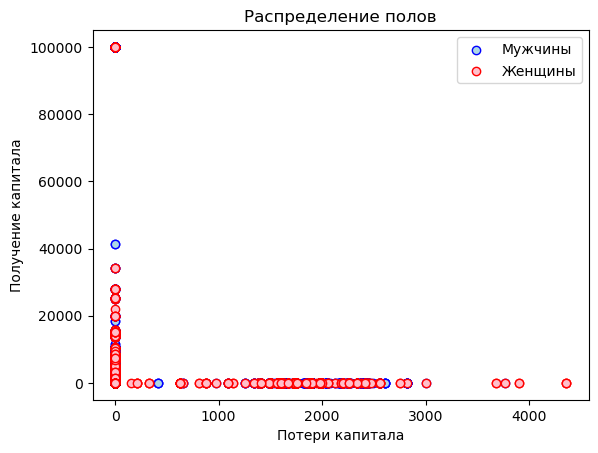

In [22]:
data_male = data[data['sex'] == 'Male']
data_female = data[data['sex'] == 'Female']

plt.scatter(data_male['capital-loss'], data_male['capital-gain'], 
            color='lightblue', edgecolors='blue', label='Мужчины')
plt.scatter(data_female['capital-loss'], data_female['capital-gain'], 
            color='pink', edgecolors='red', label='Женщины')

plt.xlabel('Потери капитала')
plt.ylabel('Получение капитала')
plt.title('Распределение полов')
plt.legend()
plt.show()

## 6. Корреляция признаков

* Использование метода корреляции в Pandas, отображаются только числовые признаки

In [23]:
data.corr(numeric_only=True)

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,-0.076646,0.036527,0.077674,0.057775,0.068756
fnlwgt,-0.076646,1.000000,-0.043195,0.000432,-0.010252,-0.018768
education-num,0.036527,-0.043195,1.000000,0.122630,0.079923,0.148123
capital-gain,0.077674,0.000432,0.122630,1.000000,-0.031615,0.078409
capital-loss,0.057775,-0.010252,0.079923,-0.031615,1.000000,0.054256
hours-per-week,0.068756,-0.018768,0.148123,0.078409,0.054256,1.000000


* Построение графика heatmap

<Axes: >

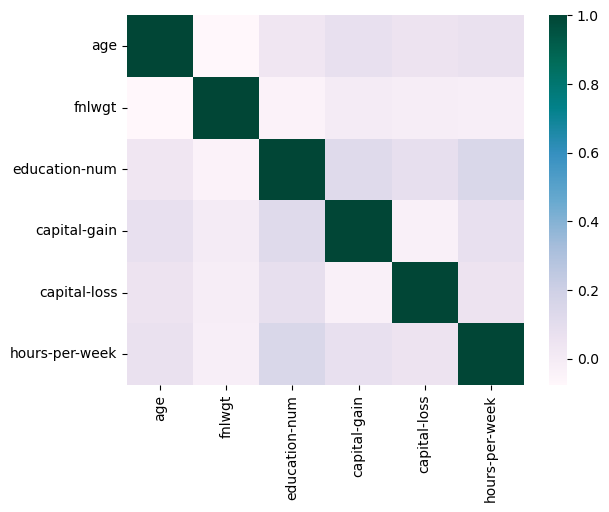

In [24]:
sns.heatmap(data.corr(numeric_only=True), cmap=plt.cm.PuBuGn)

* Удаление признаков

In [25]:
data_uncorr = data.drop(capital, axis=1)
data_uncorr.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'hours-per-week', 'native-country', 'salary'],
      dtype='object')

* Отображение нового графика heatmap

<Axes: >

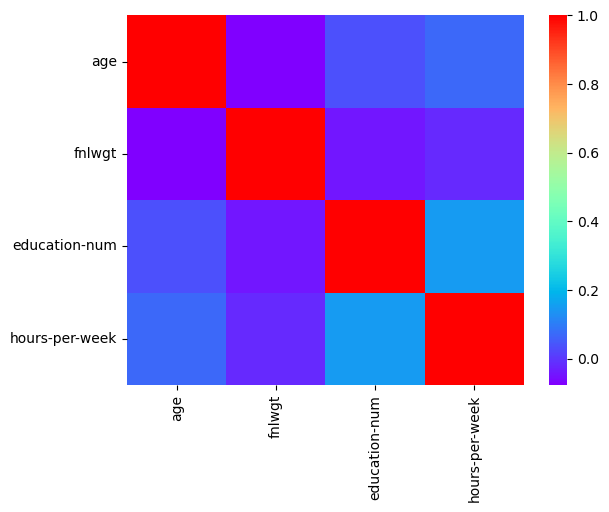

In [26]:
sns.heatmap(data_uncorr.corr(numeric_only=True), cmap=plt.cm.rainbow)